<a href="https://colab.research.google.com/github/rohillatanisha676-del/CODSOFT_TASKNO/blob/main/HANDWRITTEN_TEXT_GENERATION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
df = pd.read_csv("/content/english.csv")

print("Dataset shape:", df.shape)
print(df.head())

characters = sorted(df["label"].astype(str).unique())
print("Number of character classes:", len(characters))
print("Characters:", "".join(characters))

Dataset shape: (3410, 2)
                image label
0  Img/img001-001.png     0
1  Img/img001-002.png     0
2  Img/img001-003.png     0
3  Img/img001-004.png     0
4  Img/img001-005.png     0
Number of character classes: 62
Characters: 0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz


In [3]:
text = """
machine learning helps computers learn patterns from data.
recurrent neural networks process sequences of characters.
handwritten text generation combines text prediction and
handwritten character images to produce written sentences.
"""

# Use the character vocabulary supported by the dataset
vocab = sorted(set(text) | set(characters))
char_to_idx = {ch: i for i, ch in enumerate(vocab)}
idx_to_char = {i: ch for ch, i in char_to_idx.items()}

encoded_text = np.array([char_to_idx[ch] for ch in text])

print("Vocabulary size:", len(vocab))
print("Encoded text shape:", encoded_text.shape)

Vocabulary size: 65
Encoded text shape: (235,)


In [4]:
sequence_length = 20

X, y = [], []

for i in range(len(encoded_text) - sequence_length):
    X.append(encoded_text[i:i + sequence_length])
    y.append(encoded_text[i + sequence_length])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (215, 20)
y shape: (215,)


In [5]:
model = models.Sequential([
    layers.Input(shape=(sequence_length,)),
    layers.Embedding(len(vocab), 64),
    layers.SimpleRNN(128),
    layers.Dense(len(vocab), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 20, 64)         │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 65)             │         8,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,249 (145.50 KB)

 Trainable params: 37,249 (145.50 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    X, y,
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.0791 - loss: 3.7969
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.0977 - loss: 3.1578
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1070 - loss: 2.9742
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1116 - loss: 2.9039
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0791 - loss: 2.8897
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1302 - loss: 2.8602
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1535 - loss: 2.8323
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1395 - loss: 2.8100
Epoch 9/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2186 - loss: 2.7653
Epoch 10/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3023 - loss: 2.6804
Epoch 11/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2837 - loss: 2.5730
Epoch 12/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - 

In [7]:
def generate_text(seed, length=200, temperature=0.7):
    result = seed.lower()

    for _ in range(length):
        sequence = result[-sequence_length:]

        # Pad short sequences with spaces
        sequence = sequence.rjust(sequence_length)

        encoded = np.array([
            char_to_idx.get(ch, char_to_idx[" "])
            for ch in sequence
        ])

        prediction = model.predict(
            encoded.reshape(1, -1), verbose=0
        )[0]

        # Temperature controls randomness
        logits = np.log(prediction + 1e-8) / temperature
        probabilities = np.exp(logits - np.max(logits))
        probabilities /= probabilities.sum()

        next_idx = np.random.choice(len(vocab), p=probabilities)
        result += idx_to_char[next_idx]

    return result

print(generate_text("machine learning", length=200))

machine learningenttec  pattdare.  onteqce cetteor ceab ceos ftga  enteswon wedrMte ct
ract pr.
ranucrit  a tertteeres.
r peuctsersteron womphandwritarn chartinseritgen erimgine cearanserem
handwritten text  tneratio


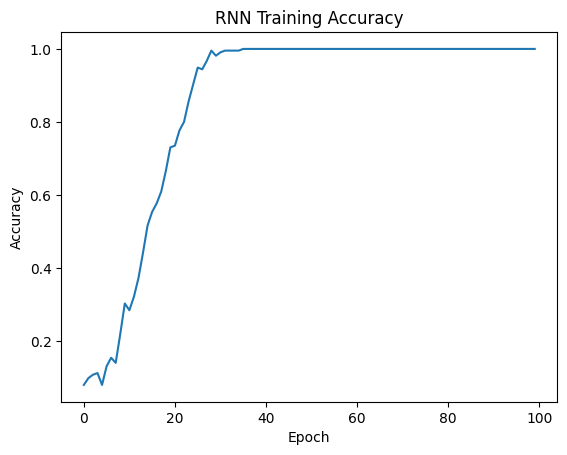

In [8]:
plt.plot(history.history["accuracy"])
plt.title("RNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()